# Tier 6: calibration to market data, hands on

Up to Tier 5 the inputs were made up: a volatility of 20%, Heston parameters picked by hand.
This tier goes the other way. It starts from option **prices** and asks which volatility, and
which model parameters, would produce them.

1. **Clean** a chain of quotes: drop the ones that would teach the fit noise.
2. **Imply the forward** of each expiry from put-call parity, instead of assuming r and q.
3. Turn each price into an **implied volatility**: the surface.
4. Fit **SVI**, a 5-number curve per expiry, and check it for arbitrage.
5. **Calibrate Heston**: one set of 5 parameters for every expiry at once.

```
src/ope/ibkr.py         fetching a chain from IBKR, read-only (not used here)
src/ope/market.py       Yahoo as fallback, and pull_chain: cache, gateway, fallback
src/ope/chain.py        a chain snapshot on disk (csv + json), and what goes in one
src/ope/surface.py      cleaning, forwards from parity, the implied vol surface
src/ope/svi.py          SVI per expiry, butterfly and calendar checks
src/ope/calibration.py  Heston on a shared quadrature grid, calibration from several starts
src/ope/synthetic.py    the synthetic chain this notebook runs on
```

**About the data.** The library pulls real SPX option chains from Interactive Brokers (read-only)
into the git-ignored `data/` folder. Real quotes stay out of git: the IBKR market data
agreement does not allow passing them on. This notebook runs on a **synthetic SPX-like chain**
that the library prices itself, with known parameters and a few deliberately broken quotes.
That also makes it a test: every step can be compared with the truth. Section 10 reports what
the same pipeline gave on a real snapshot, run locally.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

import ope
from ope.plots import plot_smiles, plot_term_structure
from ope.synthetic import JUNK, SPX_LIKE

SNAPSHOT = "../tests/fixtures/spx_synthetic.csv"  # or your own: data/chains/spx_ibkr_....csv
chain = ope.load_snapshot(SNAPSHOT)
S, R, Q = 5000.0, 0.045, 0.013  # what the synthetic chain was built with
print(f"{len(chain)} quotes, {len(chain.expiries())} expiries, as of {chain.meta['as_of']}")
print("built with Heston", SPX_LIKE)

420 quotes, 7 expiries, as of 2026-01-09T21:15:00+00:00
built with Heston HestonParams(v0=0.02, kappa=2.5, theta=0.035, xi=0.8, rho=-0.75)


## 1. A raw chain

A snapshot is one row per quote: expiry, strike, call or put, bid, ask, last trade, volume and
open interest (how many contracts are held). This one has 7 expiries from 1 week to 1 year, and
calls and puts at 30 strikes each.

Real chains are messy. Some quotes have no bid, some are crossed (bid above ask), some are old,
some are so wide they say nothing. The synthetic chain has a few of each kind on purpose:

planted junk: {'one sided': 6, 'crossed': 4, 'stale': 5, 'wide': 5, 'no interest': 6, 'out of bounds': 3}


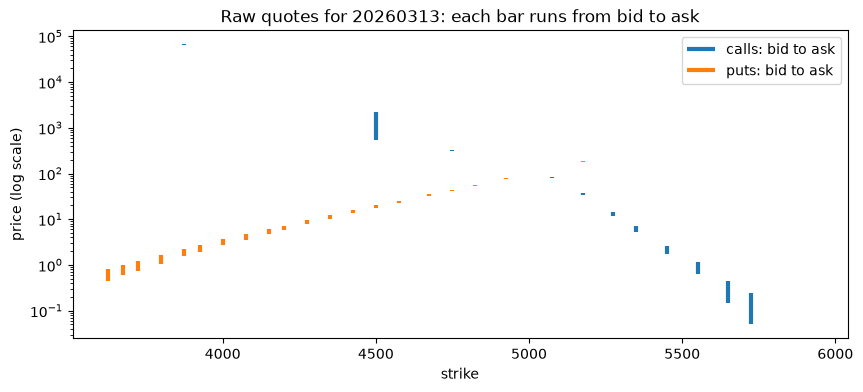

In [2]:
print("planted junk:", JUNK)
e = chain.expiries()[3]
m = chain.expiry == e
fig, ax = plt.subplots(figsize=(10, 4))
for right, color in (("C", "tab:blue"), ("P", "tab:orange")):
    mm = m & (chain.right == right)
    ax.vlines(
        chain.strike[mm],
        chain.bid[mm],
        chain.ask[mm],
        color=color,
        lw=3,
        label=f"{'calls' if right == 'C' else 'puts'}: bid to ask",
    )
ax.set_yscale("log")
ax.set_xlabel("strike")
ax.set_ylabel("price (log scale)")
ax.set_title(f"Raw quotes for {e}: each bar runs from bid to ask")
ax.legend()
plt.show()

## 2. Cleaning, with a count for every filter

The filters run in this order, and each one reports how many quotes it removed:

| Filter | Drops a quote when |
|---|---|
| no two-sided quote | the bid or the ask is missing |
| crossed or locked | bid ≥ ask: no real market looks like that |
| stale | its last trade is more than 5 days old |
| wide spread | (ask − bid) / mid > 0.5: the quote says little about the price |
| no volume, no open interest | nobody traded it today **and** nobody holds it |
| outside no-arbitrage bounds | the mid is below intrinsic value or above the stock (or strike) |
| in-the-money side | not junk: by parity the out-of-the-money option carries the same vol |

Two choices here came from the real SPX snapshot. Dropping every quote with zero volume would
have removed 57% of the real two-sided quotes, many of them tight, long-dated quotes that market
makers keep up to date. And a missing open interest means "unknown": IBKR sends it after
the quote, and it was missing on half the 9-month quotes.

In [3]:
surface = ope.iv_surface(chain)
print("\n".join(surface.report.lines()))

raw quotes                     420
  - no two sided quote          26
  - crossed or locked            4
  - stale                        5
  - wide spread                 33
  - no volume, no open interest     6
  - expiry w/o a forward         0
  - outside no arbitrage bounds     9
  - in the money side (parity)   184  (not junk, the otm side carries the same vol)
kept                           153


Every planted quote was caught by its own filter (the test suite checks each one by
identity). The counts are bigger than the planted junk because real-looking quotes fail too:
very cheap wing options with a one-tick bid are "wide", and some deep in-the-money mids round
below intrinsic value.

## 3. The forward, from the options themselves

Put-call parity holds in any model: a call minus a put at the same strike is a forward contract.

C − P = D·(F − K) = D·F − D·K

So C − P is a **straight line in K**. Its slope is −D (the discount factor) and its intercept is
D·F. A regression over all the strikes gives both, with no r and no q assumed. Each pair is
weighted by 1 / (its two spreads), and a pair far from the line (more than twice its spread) is
dropped, the worst first, so one bad quote cannot drag the line.

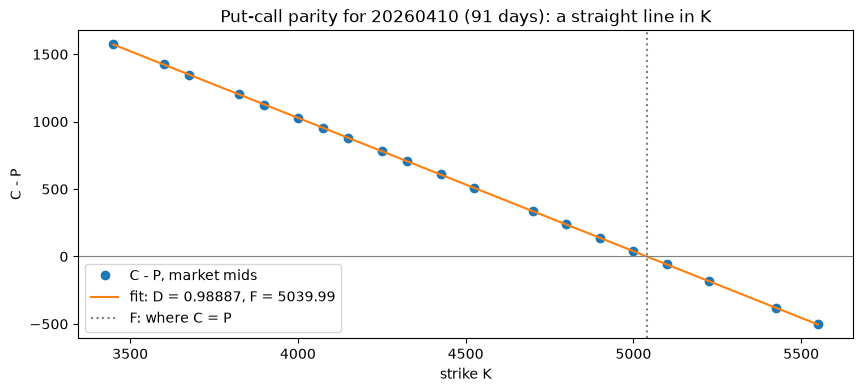

In [4]:
clean, _ = ope.clean_chain(chain, liquidity=False)
e = clean.expiries()[4]
m = clean.expiry == e
calls = {k: i for i in np.flatnonzero(m & (clean.right == "C")) for k in [clean.strike[i]]}
puts = {k: i for i in np.flatnonzero(m & (clean.right == "P")) for k in [clean.strike[i]]}
ks = np.array(sorted(set(calls) & set(puts)))
y = np.array([clean.mid[calls[k]] - clean.mid[puts[k]] for k in ks])
f = surface.forwards[e]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ks, y, "o", label="C - P, market mids")
ax.plot(ks, f.D * (f.F - ks), "-", label=f"fit: D = {f.D:.5f}, F = {f.F:.2f}")
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(f.F, color="gray", ls=":", label="F: where C = P")
ax.set_xlabel("strike K")
ax.set_ylabel("C - P")
ax.set_title(f"Put-call parity for {e} ({f.T * 365:.0f} days): a straight line in K")
ax.legend()
plt.show()

In [5]:
print(f"{'expiry':>9} {'days':>5} {'F':>9} {'true F':>9} {'r':>7} {'q':>7} {'pairs':>5}")
for e, f in surface.forwards.items():
    F_true = S * math.exp((R - Q) * f.T)
    print(
        f"{e:>9} {f.T * 365:5.0f} {f.F:9.2f} {F_true:9.2f} {f.r * 100:6.2f}% "
        f"{f.q(S) * 100:6.2f}% {f.n_pairs:5d}"
    )
print(f"truth: r = {R:.2%}, q = {Q:.2%}")

   expiry  days         F    true F       r       q pairs
 20260116     7   5003.08   5003.06   4.51%   1.30%    16
 20260123    14   5006.13   5006.14   4.57%   1.37%    19
 20260206    28   5012.30   5012.28   4.51%   1.31%    21
 20260313    63   5027.71   5027.67   4.49%   1.28%    19
 20260410    91   5039.99   5040.03   4.49%   1.30%    20
 20260710   182   5080.18   5080.40   4.46%   1.27%    20
 20270108   364   5161.85   5162.13   4.49%   1.29%    25
truth: r = 4.50%, q = 1.30%


The forward comes back within 1 basis point at every expiry, and r and q within 0.07%. At 1
week D = 0.999, so the slope barely differs from 1 and r there is partly luck: on the real
snapshot the 1-week r came out at 3.0% while the longer expiries agreed on 4.6% to 5.2%. That
costs almost nothing, since a 0.001 error in D moves a price by 0.1%.

**Assuming r and q fails here.** On the real snapshot, the SPX index level IBKR returned was out
of sync with the option quotes (the index stops at 16:00, the options trade until 16:15). With
that level, the 1-week dividend yield came out at −10%, which is impossible. The options carry
their own forward, and the library reads it from them. Here is what a wrong forward does to the smile:

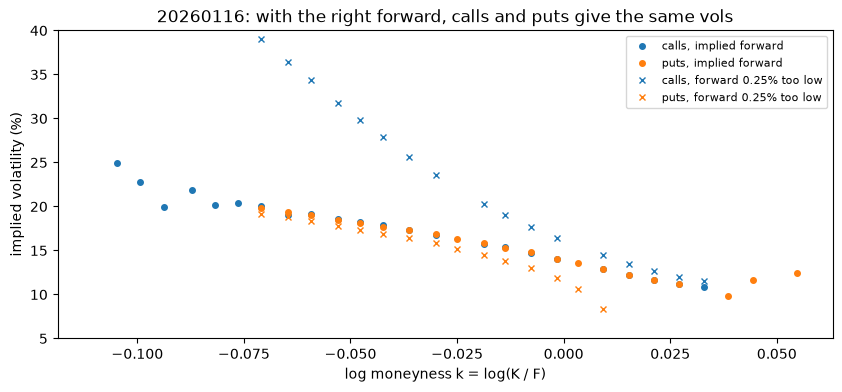

In [6]:
e = surface.expiries()[0]
f = surface.forwards[e]
wrong_F = f.F * (1 - 0.0025)  # 0.25% off: about 12 index points at 5000
clean_e = clean.select(clean.expiry == e)
fig, ax = plt.subplots(figsize=(10, 4))
for F, style, label in ((f.F, "o", "implied forward"), (wrong_F, "x", "forward 0.25% too low")):
    for right, color in (("C", "tab:blue"), ("P", "tab:orange")):
        mm = clean_e.right == right
        vols = []
        for K, mid in zip(clean_e.strike[mm], clean_e.mid[mm], strict=True):
            try:
                vols.append(
                    ope.implied_vol(
                        "call" if right == "C" else "put",
                        float(mid),
                        f.D * F,
                        float(K),
                        f.T,
                        f.r,
                        0.0,
                    )
                )
            except ValueError:
                vols.append(np.nan)
        ax.plot(
            np.log(clean_e.strike[mm] / f.F),
            100 * np.array(vols),
            style,
            color=color,
            ms=4,
            label=f"{'calls' if right == 'C' else 'puts'}, {label}",
        )
ax.set_ylim(5, 40)
ax.set_xlabel("log moneyness k = log(K / F)")
ax.set_ylabel("implied volatility (%)")
ax.set_title(f"{e}: with the right forward, calls and puts give the same vols")
ax.legend(fontsize=8)
plt.show()

With the implied forward, the call and put vols at each strike sit on one smile. With a
forward 0.25% off, they split apart by 4.5 to 6 vol points near the money, and at one strike
the put has no vol at all: its price is below the "intrinsic value" the wrong forward implies.
Even 0.1% off splits them by 2 to 3 vol points.

Look also at the calls on the far left, deep in the money: even with the right forward their vols
jump around (20% to 25%). Their price is almost all intrinsic value, so one tick of noise is a
large share of the little time value left. That is the other reason the rest
of the notebook keeps the out-of-the-money side: puts below F, calls above.

## 4. The implied volatility surface

Each kept mid becomes an implied vol (the Tier 1 solver, with S = D·F, r from D and q = 0, which
reproduces the forward). The bid and the ask become vols too: their gap is how much the market
itself knows about that point, and the fits weight each quote by 1 / (that gap).

Log moneyness k = log(K / F) puts every expiry on the same scale: k = 0 is at the money,
k = −0.1 is a strike 10% below the forward.

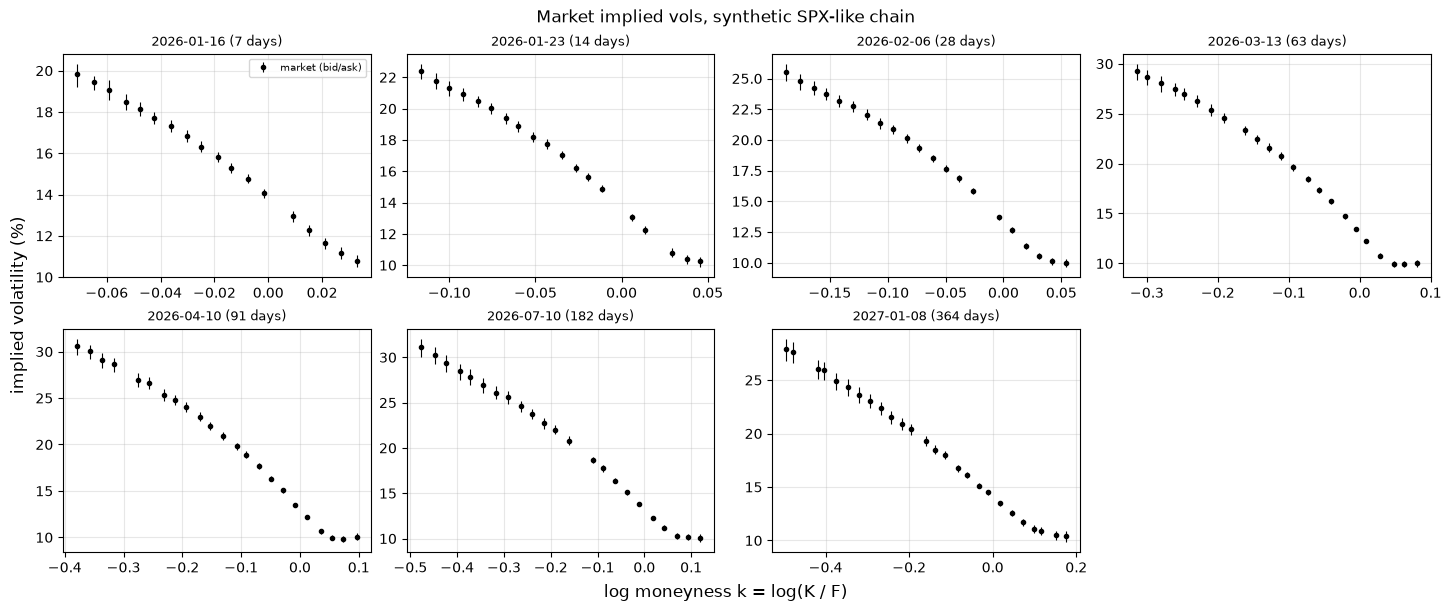

In [7]:
plot_smiles(surface, title="Market implied vols, synthetic SPX-like chain")

Every expiry shows the equity skew: low strikes (crash protection) cost more vol than high
ones. It is steepest at the short end.

## 5. SVI: one curve per expiry

SVI ("stochastic volatility inspired", Gatheral 2004) describes the **total implied variance**
w = σ²·T of one expiry with 5 numbers:

w(k) = a + b·( ρ·(k − m) + √((k − m)² + σ²) )

a sets the level, b the slope of the wings, ρ the tilt (ρ < 0 is the equity skew), m shifts the
curve, σ rounds its bottom. Far from the money w is a straight line in k, as Roger Lee proved it
must be.

The fit minimizes the vol errors times the weights, from 12 starting points. Lee's wing bound
b·(1 + |ρ|) ≤ 2 is part of every fit: on the real snapshot it cost at most 0.001 vol points.

In [8]:
fits = ope.fit_svi_surface(surface)
print(f"{'expiry':>9} {'days':>5} {'n':>3} {'rms':>6} {'max':>6} {'in bid/ask':>10} {'min g':>7}")
for fit in fits:
    print(
        f"{fit.expiry:>9} {fit.T * 365:5.0f} {fit.n:3d} {fit.rms:6.3f} {fit.max_abs:6.3f} "
        f"{fit.within_spread * 100:9.0f}% {fit.min_g:7.3f}"
    )
print("errors in vol points (1 = 1% of vol)")

   expiry  days   n    rms    max in bid/ask   min g
 20260116     7  18  0.061  0.115       100%   0.520
 20260123    14  19  0.121  0.255       100%   0.436
 20260206    28  21  0.181  0.429       100%   0.370
 20260313    63  23  0.181  0.471       100%   0.321
 20260410    91  23  0.155  0.387       100%   0.306
 20260710   182  23  0.103  0.202       100%   0.299
 20270108   364  26  0.080  0.153       100%   0.313
errors in vol points (1 = 1% of vol)


### Butterfly arbitrage: g(k) ≥ 0

A curve can match every quote and still be impossible. The price of a butterfly (long the
strikes K − h and K + h, short 2 at K) is, in the limit, the probability density of the price at
expiry. It cannot be negative. For an SVI curve, Gatheral and Jacquier turned this into one
function of k:

g(k) = (1 − k·w′/(2w))² − (w′²/4)·(1/w + 1/4) + w″/2  ≥ 0

The density of k is g(k)/√(2πw)·exp(−d₂²/2), so g < 0 anywhere means a negative probability.
Axel Vogt found a set of SVI parameters that looks harmless and breaks it:

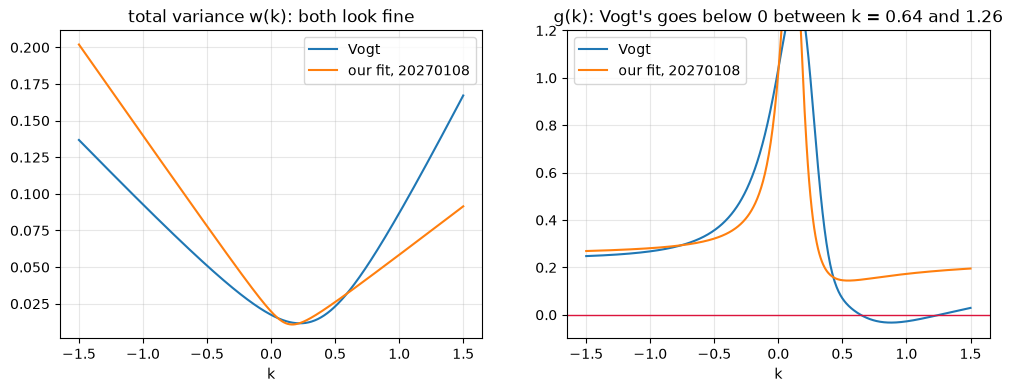

In [9]:
vogt = ope.SVIParams(-0.0410, 0.1331, 0.3060, 0.3586, 0.4153)
k = np.linspace(-1.5, 1.5, 601)
fig, (ax_w, ax_g) = plt.subplots(1, 2, figsize=(12, 4))
ax_w.plot(k, vogt.w(k), label="Vogt")
ax_w.plot(k, fits[-1].params.w(k), label=f"our fit, {fits[-1].expiry}")
ax_w.set_title("total variance w(k): both look fine")
ax_g.plot(k, vogt.g(k), label="Vogt")
ax_g.plot(k, fits[-1].params.g(k), label=f"our fit, {fits[-1].expiry}")
ax_g.axhline(0, color="crimson", lw=1)
ax_g.set_ylim(-0.1, 1.2)
ax_g.set_title("g(k): Vogt's goes below 0 between k = 0.64 and 1.26")
for ax in (ax_w, ax_g):
    ax.set_xlabel("k")
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()

g is checked on each expiry's quoted range plus 10% of its width on each side, where the
data pins the curve down. If it goes negative there, the expiry is refit with a penalty on the
violation, and the fit says so (`penalized`). Far outside the quotes, a curve fitted to a narrow
range can bend anywhere: on the real 1-week slice g reached −86 at k = −0.35, three times past
the lowest quote. That is reported as a flag (`min_g_wide`).

### Calendar arbitrage: w never decreases with T

A longer option holds every possibility of a shorter one and more, so the total variance at any
k must not fall from one expiry to the next. Each expiry is fitted above the previous one where
their ranges overlap, with a penalty when the plain fit crosses it.

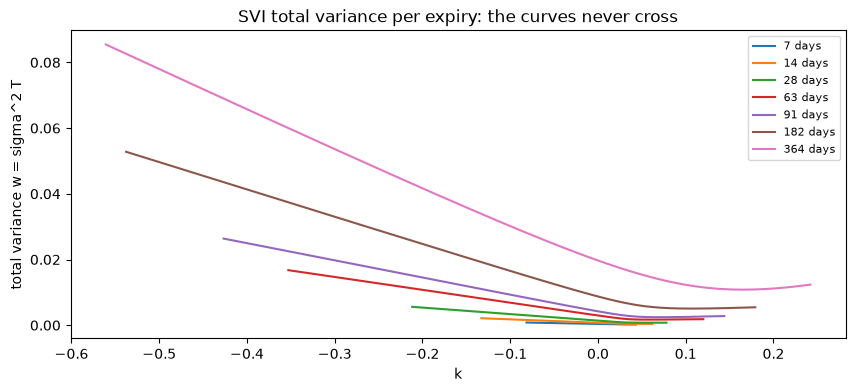

20260116 -> 20260123: smallest gap +0.000188 at k = +0.04
20260123 -> 20260206: smallest gap +0.000367 at k = +0.06
20260206 -> 20260313: smallest gap +0.000935 at k = +0.06
20260313 -> 20260410: smallest gap +0.000720 at k = +0.08
20260410 -> 20260710: smallest gap +0.002408 at k = +0.14
20260710 -> 20270108: smallest gap +0.005422 at k = +0.18


In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
for fit in fits:
    kk = fit.k_check()
    ax.plot(kk, fit.params.w(kk), label=f"{fit.T * 365:.0f} days")
ax.set_xlabel("k")
ax.set_ylabel("total variance w = sigma^2 T")
ax.set_title("SVI total variance per expiry: the curves never cross")
ax.legend(fontsize=8)
plt.show()
for c in ope.calendar_checks(fits):
    print(f"{c.expiry_1} -> {c.expiry_2}: smallest gap {c.min_gap:+.6f} at k = {c.at_k:+.2f}")

### How much SVI's parameters mean

SVI fits a curve. With noise of 0.3 vol points over a strike range like a
6-month SPX slice, ρ can come back anywhere between −0.4 and −0.9 while the curve stays within
0.3 vol points. Without noise, the parameters come back to 1e-6:

In [11]:
truth = ope.SVIParams(0.012, 0.08, -0.7, 0.02, 0.12)
kq = np.linspace(-0.45, 0.2, 25)
for noise in (0.0, 0.003):
    vol = np.asarray(truth.vol(kq, 0.5)) + np.random.default_rng(1).normal(0, noise, kq.size)
    p = ope.fit_svi(kq, vol, 0.5).params
    curve = np.max(np.abs(np.asarray(p.vol(kq, 0.5)) - np.asarray(truth.vol(kq, 0.5)))) * 100
    print(
        f"noise {noise * 100:.1f} vol pts: rho {p.rho:+.3f} (true -0.700), "
        f"curve within {curve:.3f} vol pts"
    )

noise 0.0 vol pts: rho -0.700 (true -0.700), curve within 0.000 vol pts
noise 0.3 vol pts: rho -0.917 (true -0.700), curve within 0.293 vol pts


## 6. Heston, calibrated to the whole surface

Heston (Tier 5) has 5 parameters: v₀ (variance today), κ (how fast it returns), θ (where it
returns to), ξ (vol of vol) and ρ (stock-vol correlation). Here one set has to fit **every
expiry at once**, which is a real test of the model.

**Speed.** `heston_price` takes 4 to 9 ms per strike: two adaptive integrals each. A calibration
evaluates the whole surface hundreds of times, so the integrals here use **one shared grid per
expiry**: the characteristic function is computed once on the grid nodes, and each strike is then
one row of a matrix product. The number of nodes follows how fast e^(−iu·log(K/F)) turns.

In [12]:
import time

from ope.calibration import heston_grid_prices

T, F, D = 0.5, 5100.0, 0.98
K = F * np.exp(np.linspace(-0.4, 0.2, 25))
t0 = time.perf_counter()
grid = heston_grid_prices("call", F, D, T, K, SPX_LIKE)
t_grid = time.perf_counter() - t0
t0 = time.perf_counter()
ref = ope.heston_price("call", D * F, K, T, -math.log(D) / T, SPX_LIKE)
t_quad = time.perf_counter() - t0
print(
    f"largest gap to heston_price: {np.max(np.abs(grid - ref)):.1e} (prices up to {ref.max():.0f})"
)
print(f"25 strikes: shared grid {t_grid * 1e3:.1f} ms, heston_price {t_quad * 1e3:.0f} ms")

largest gap to heston_price: 1.6e-07 (prices up to 1656)
25 strikes: shared grid 314.7 ms, heston_price 174 ms


**The objective.** For each quote, the model price minus the mid, divided by the
Black-Scholes vega at the market vol. Price error / vega ≈ vol error, so the fit works in vol
points without inverting a model price inside the loop. Each error is weighted by 1 / (the
quote's bid-ask spread in vol), so a wide wing quote counts less than a tight one.

**Several starts.** The Heston fit has flat valleys (a fast pull back with more noise looks like
a slow one with less), so one start can stop early and look converged. 8 starting points come
from a seeded Sobol sequence, and every one is reported.

In [13]:
cal = ope.calibrate_heston(surface, n_starts=8, seed=0)


def show(p):
    return f"v0 {p.v0:.4f} kappa {p.kappa:.3f} theta {p.theta:.4f} xi {p.xi:.3f} rho {p.rho:+.3f}"


for s in cal.starts:
    print(f"start {show(s.start)}  ->  {show(s.params)}")
p = cal.params
print(f"\nfitted: {show(p)}")
print(f"truth:  {show(SPX_LIKE)}")
print(
    f"Feller: 2·kappa·theta = {2 * p.kappa * p.theta:.3f} vs xi² = {p.xi**2:.3f} -> "
    f"{'holds' if cal.feller else 'violated'}"
)
print(f"{cal.seconds:.1f} s for {len(cal.starts)} starts")

start v0 0.1283 kappa 5.623 theta 0.0576 xi 0.674 rho -0.831  ->  v0 0.0200 kappa 2.483 theta 0.0351 xi 0.797 rho -0.751
start v0 0.0098 kappa 2.068 theta 0.0961 xi 1.169 rho -0.334  ->  v0 0.0200 kappa 2.483 theta 0.0351 xi 0.797 rho -0.751
start v0 0.0646 kappa 4.081 theta 0.0298 xi 0.312 rho -0.114  ->  v0 0.0200 kappa 2.483 theta 0.0351 xi 0.797 rho -0.751
start v0 0.1093 kappa 0.505 theta 0.1272 xi 1.447 rho -0.625  ->  v0 0.0200 kappa 2.483 theta 0.0351 xi 0.797 rho -0.751
start v0 0.0931 kappa 3.550 theta 0.0799 xi 1.197 rho -0.719  ->  v0 0.0200 kappa 2.483 theta 0.0351 xi 0.797 rho -0.751
start v0 0.0471 kappa 1.432 theta 0.0730 xi 0.402 rho -0.209  ->  v0 0.0200 kappa 2.483 theta 0.0351 xi 0.797 rho -0.751
start v0 0.0299 kappa 4.737 theta 0.1428 xi 0.927 rho -0.429  ->  v0 0.0200 kappa 2.483 theta 0.0351 xi 0.797 rho -0.751
start v0 0.1471 kappa 2.640 theta 0.0136 xi 0.751 rho -0.926  ->  v0 0.0200 kappa 2.483 theta 0.0351 xi 0.797 rho -0.751

fitted: v0 0.0200 kappa 2.483 t

In [14]:
print(f"{'expiry':>9} {'days':>5} {'n':>3} {'rms':>6} {'max':>6} {'in bid/ask':>10}")
for err in cal.errors:
    print(
        f"{err.expiry:>9} {err.T * 365:5.0f} {err.n:3d} {err.rms:6.3f} {err.max_abs:6.3f} "
        f"{err.within_spread * 100:9.0f}%"
    )
print(f"all quotes: rms {cal.rms:.3f} vol points")

   expiry  days   n    rms    max in bid/ask
 20260116     7  18  0.047  0.074       100%
 20260123    14  19  0.055  0.100       100%
 20260206    28  21  0.072  0.121       100%
 20260313    63  23  0.075  0.162       100%
 20260410    91  23  0.094  0.206       100%
 20260710   182  23  0.110  0.226       100%
 20270108   364  26  0.076  0.161       100%
all quotes: rms 0.080 vol points


All 8 starts land on the same point, close to the truth, and the remaining error is the
noise planted in the quotes: every model vol sits inside its bid-ask. The Feller condition is
violated, as it is in the truth and in most real index calibrations: the variance can touch 0.

## 7. Both fits on the smile

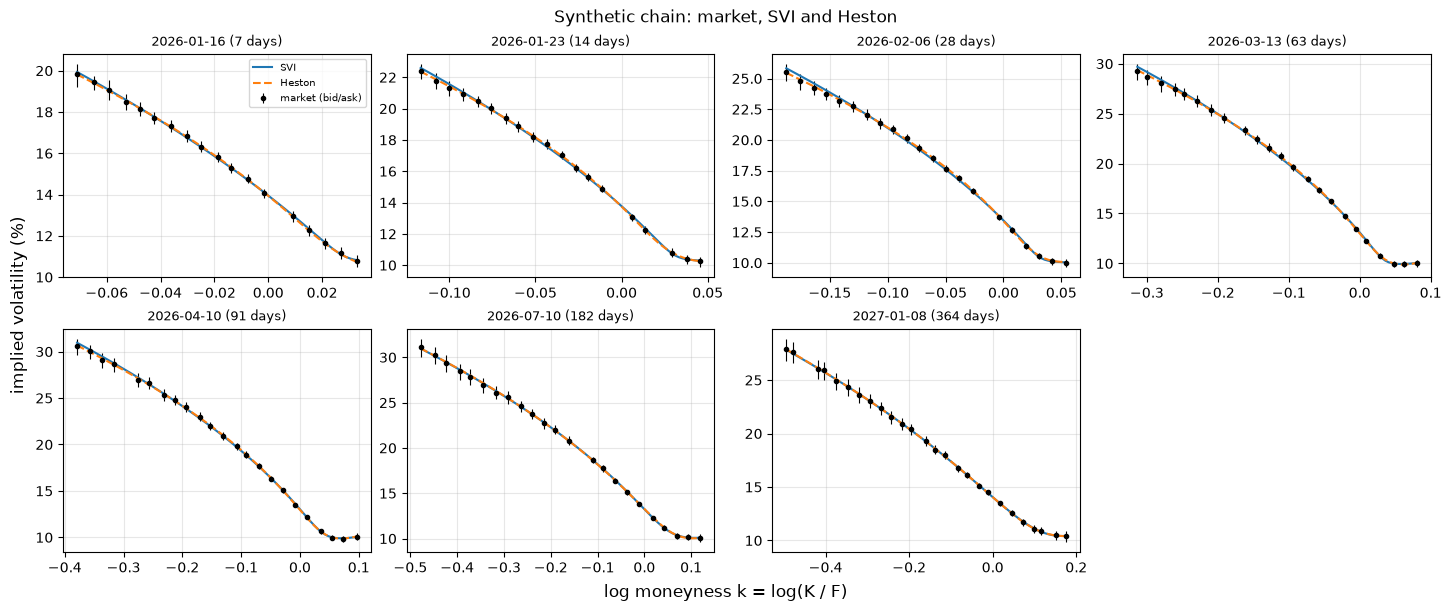

In [15]:
plot_smiles(surface, fits, cal, title="Synthetic chain: market, SVI and Heston")

## 8. The term structure of the smile

From the SVI fits: the at-the-money vol per expiry, and the at-the-money **skew**, the slope
dσ/dk at k = 0 (here in vol points per 10% of moneyness). The skew is steepest at the short end
and flattens with maturity.

On this Heston-made chain the skew barely moves over the first month (−10.2 at 1 week, −9.5 at
1 month), then falls to −3.4 at 1 year. On the real snapshot it keeps steepening toward the short
end: −12.3 at 1 week, −9.0 at 1 month, −3.5 at 1 year. Heston's skew levels off at short
maturities and the market's doesn't, which is the short-end miss of section 10 seen from
another side.

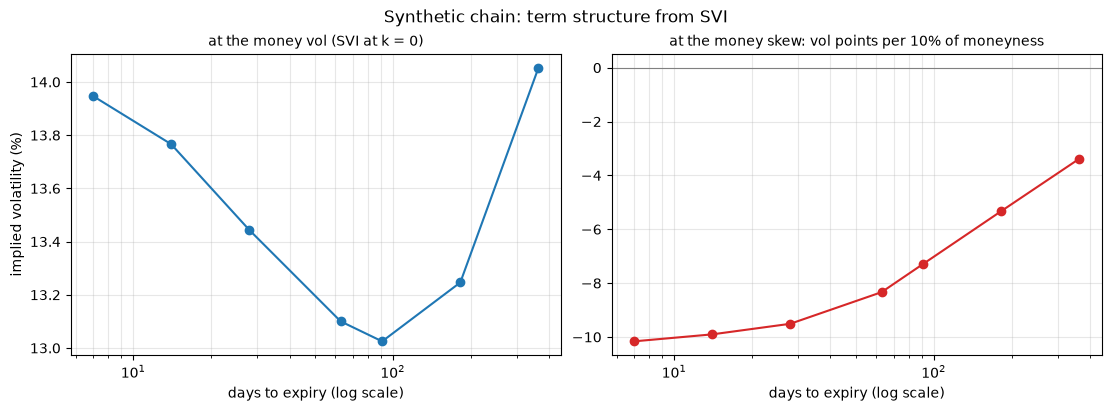

In [16]:
plot_term_structure(surface, fits, title="Synthetic chain: term structure from SVI")

## 9. Same snapshot, same numbers

Nothing in the pipeline is random except the Sobol starting points, which are seeded. Running
the whole calibration again from the file gives the same parameters, bit for bit.

In [17]:
again = ope.calibrate_heston(ope.iv_surface(ope.load_snapshot(SNAPSHOT)), n_starts=8, seed=0)
print("same params, bit for bit:", again.params == cal.params)

same params, bit for bit: True


## 10. On a real SPX snapshot (run locally, results only)

The same pipeline, run on a real SPXW chain pulled from Interactive Brokers (delayed data, the
close of 23 October 2026, 8 expiries from 7 to 342 days). The results are shown here, the quotes
are not.

**Cleaning:** 392 quotes → 62 without a two-sided quote, 0 crossed, 0 stale (the source gives no
trade times), 4 too wide, 47 with no volume and no open interest, 1 outside the bounds, 120 on the
in-the-money side → **158 kept**. Past 1 month the implied rate came out between 4.6% and 5.2%.

**SVI, error per expiry in vol points:**

| Days | 7 | 14 | 31 | 56 | 84 | 159 | 250 | 342 |
|---|---|---|---|---|---|---|---|---|
| rms | 0.387 | 0.130 | 0.094 | 0.093 | 0.115 | 0.137 | 0.038 | 0.003 |
| max | 1.793 | 0.412 | 0.250 | 0.217 | 0.253 | 0.221 | 0.076 | 0.004 |

No butterfly arbitrage on any quoted range, no calendar crossing, Lee's bound met everywhere.

**Heston:** all 8 starts gave the same point: v₀ = 0.0287 (16.9% vol), κ = 4.80, θ = 0.0503
(22.4% vol), ξ = 1.78, ρ = −0.687. Feller violated (2κθ = 0.48 vs ξ² = 3.15). 4 to 7 seconds.

| Days | 7 | 14 | 31 | 56 | 84 | 159 | 250 | 342 |
|---|---|---|---|---|---|---|---|---|
| rms | 2.569 | 1.825 | 0.886 | 1.026 | 1.174 | 1.114 | 0.286 | 0.068 |
| max | 7.266 | 5.375 | 2.124 | 2.621 | 2.863 | 2.150 | 0.891 | 0.191 |

SVI fits every expiry; Heston fits the long end and misses the short one by up to 7 vol points.
That is the model's known limit: with no jumps, its variance cannot move fast enough to make a
37%-to-12% skew within one week. Jump models (Bates) or rough volatility address it.

**To run it on your own data:** start IB Gateway (or TWS) with the API enabled in read-only
mode, then `ope fetch-chain --port <your API port>` (or set `OPE_IB_PORT`), and point
`SNAPSHOT` above at the file it writes in `data/chains/`.

## 11. Try it yourself

1. In section 2, call `ope.iv_surface(chain, max_rel_spread=0.2)`. Which filter count changes,
   and how many quotes does the surface lose?
2. Fit SVI to one expiry yourself with `ope.fit_svi(k, iv, T, weights)`, using the `surface`
   arrays for that expiry (`surface.rows(e)` gives the mask). Compare with `fits`.
3. Calibrate Heston with `n_starts=1` and different `seed` values. Does every start find
   the same point on this chain?
4. In section 3, try a forward 0.1% off instead of 0.25%. How many vol points do the calls and
   puts split by near the money?

In [18]:
# your code here